# 03 · Advertised price prediction

## Purpose

This notebook develops and compares regression models for predicting the advertised nightly price of NYC Airbnb listings.

The models use listing characteristics available in the processed dataset and are evaluated on a held-out test set. The target is modelled on a base-10 logarithmic scale to reduce the influence of the strongly right-skewed price distribution. Predictions are converted back to US dollars for practical evaluation.

The analysis focuses on advertised price prediction. It does not estimate an optimal price, booking probability, occupancy or revenue.

## 1. Imports

The modelling workflow uses scikit-learn for preprocessing, linear models, Random Forest and model evaluation. CatBoost is included as the boosted-tree comparison because it can work directly with categorical variables.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from catboost import CatBoostRegressor
except ImportError as exc:
    raise ImportError(
        "CatBoost is required for this notebook. Install the 'catboost' package before running it."
    ) from exc

warnings.filterwarnings("ignore", category=UserWarning)

## 2. Configuration

The test set is held back from model fitting and tuning. Cross-validation is carried out only on the training data. The final model is selected using cross-validation performance and is then evaluated once on the test set.

In [2]:
RANDOM_SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airbnb_cleaned_features.csv"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "pricing"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = PROJECT_ROOT / "models" / "pricing"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CORE_CATEGORICAL = [
    "room_type",
    "neighbourhood_group",
    "neighbourhood",
]

CORE_NUMERICAL = [
    "dist_center_km",
]

EXTENDED_CATEGORICAL = CORE_CATEGORICAL.copy()

EXTENDED_NUMERICAL = CORE_NUMERICAL + [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "dist_nbhd_center_km",
    "has_reviews",
]

TARGET_COLUMN = "price"

ELASTIC_PARAM_GRID = {
    "model__alpha": [0.0005, 0.001, 0.005, 0.01, 0.05],
    "model__l1_ratio": [0.10, 0.50, 0.90],
}

RF_PARAM_DISTRIBUTIONS = {
    "model__n_estimators": [250, 300],
    "model__max_depth": [None, 12, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
}

RF_SEARCH_ITERATIONS = 3

CATBOOST_CANDIDATES = [
    {
        "iterations": 350,
        "depth": 6,
        "learning_rate": 0.05,
        "l2_leaf_reg": 3,
    },
    {
        "iterations": 350,
        "depth": 8,
        "learning_rate": 0.05,
        "l2_leaf_reg": 3,
    },
    {
        "iterations": 300,
        "depth": 6,
        "learning_rate": 0.10,
        "l2_leaf_reg": 5,
    },
]

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 3. Load and check the data

The modelling dataset is checked for the variables required by the pricing models. Listings with non-positive prices cannot be represented on the logarithmic scale and are excluded if any remain.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}\n"
        "Update DATA_PATH in the configuration cell if the file is stored elsewhere."
    )

df = pd.read_csv(DATA_PATH)

required_columns = set(
    [TARGET_COLUMN]
    + CORE_CATEGORICAL
    + EXTENDED_NUMERICAL
)

missing_columns = sorted(required_columns.difference(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

pricing_df = df.loc[df[TARGET_COLUMN].gt(0)].copy()

print(f"Rows loaded: {len(df):,}")
print(f"Rows retained for price modelling: {len(pricing_df):,}")
print(f"Columns: {pricing_df.shape[1]}")

missing_summary = (
    pricing_df[
        EXTENDED_CATEGORICAL + EXTENDED_NUMERICAL + [TARGET_COLUMN]
    ]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing")
)

display(missing_summary)

Rows loaded: 31,340
Rows retained for price modelling: 31,340
Columns: 34


,missing
room_type,0
neighbourhood_group,0
neighbourhood,0
dist_center_km,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0
availability_365,0
dist_nbhd_center_km,0


## 4. Target definition

Advertised price is strongly right-skewed, so the regression target is `log10(price)`. This reduces the influence of very high-price listings while keeping the transformation easy to reverse.

All final predictions are converted back to dollars before business-facing error measures are reported.

,count,mean,std,min,25%,50%,75%,max
price,"31,340.0000",162.1028,254.4935,10.0000,70.0000,112.0000,189.0000,"10,000.0000"
model_log_price,"31,340.0000",2.0711,0.3128,1.0000,1.8451,2.0492,2.2765,4.0000


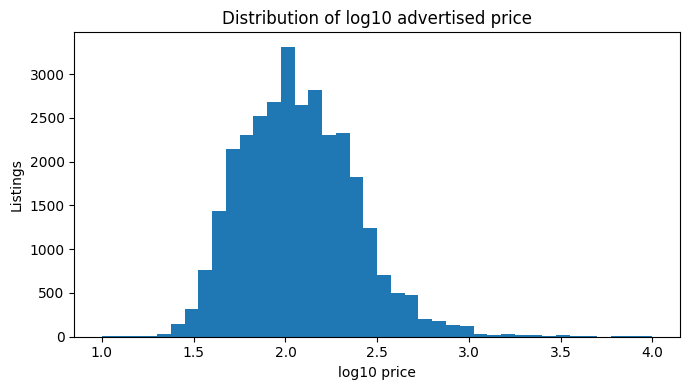

In [4]:
pricing_df["model_log_price"] = np.log10(
    pricing_df[TARGET_COLUMN].astype(float)
)

target_summary = pricing_df[
    [TARGET_COLUMN, "model_log_price"]
].describe().T

display(target_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pricing_df["model_log_price"], bins=40)
ax.set_title("Distribution of log10 advertised price")
ax.set_xlabel("log10 price")
ax.set_ylabel("Listings")
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "log_price_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 5. Predictor selection and leakage control

The main predictors are divided into a structural core and an extended feature set.

The core contains room type and location. The extended set adds minimum stay, review activity, host listing count, availability and distance from the neighbourhood centre.

Variables derived directly from advertised price are not used as predictors. Price-based neighbourhood tiers, neighbourhood median price measures and price-derived luxury indicators are excluded. Identifiers, names and the demand-rate variable are also excluded from the pricing models.

In [5]:
excluded_price_derived = [
    "nbhd_median_price",
    "nbhd_price_tier",
    "nbhd_price_premium",
    "is_luxury",
    "luxury_score",
    "is_luxury_v2",
]

excluded_other = [
    "id",
    "name",
    "host_id",
    "host_name",
    "log_price",
    "demand_rate_year",
    "est_reviews_per_year",
    "availability_bucket",
    "stay_regime",
    "close_to_center",
]

feature_table = pd.DataFrame(
    {
        "feature": EXTENDED_CATEGORICAL + EXTENDED_NUMERICAL,
        "type": (
            ["categorical"] * len(EXTENDED_CATEGORICAL)
            + ["numerical"] * len(EXTENDED_NUMERICAL)
        ),
        "feature_set": [
            "core" if feature in CORE_CATEGORICAL + CORE_NUMERICAL else "extended"
            for feature in EXTENDED_CATEGORICAL + EXTENDED_NUMERICAL
        ],
    }
)

display(feature_table)

,feature,type,feature_set
0,room_type,categorical,core
1,neighbourhood_group,categorical,core
2,neighbourhood,categorical,core
3,dist_center_km,numerical,core
4,minimum_nights,numerical,extended
5,number_of_reviews,numerical,extended
6,reviews_per_month,numerical,extended
7,calculated_host_listings_count,numerical,extended
8,availability_365,numerical,extended
9,dist_nbhd_center_km,numerical,extended


## 6. Train-test split

The data is divided into training and test sets before any preprocessing is fitted. The test set remains untouched during model tuning.

The same split is used for every model so that performance is directly comparable.

In [6]:
X = pricing_df[
    EXTENDED_CATEGORICAL + EXTENDED_NUMERICAL
].copy()

y_log = pricing_df["model_log_price"].copy()
y_price = pricing_df[TARGET_COLUMN].astype(float).copy()

train_index, test_index = train_test_split(
    np.arange(len(pricing_df)),
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
)

X_train = X.iloc[train_index].copy()
X_test = X.iloc[test_index].copy()

y_train_log = y_log.iloc[train_index].copy()
y_test_log = y_log.iloc[test_index].copy()

y_train_price = y_price.iloc[train_index].copy()
y_test_price = y_price.iloc[test_index].copy()

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(
    f"Training median price: ${y_train_price.median():,.2f}"
)
print(
    f"Test median price: ${y_test_price.median():,.2f}"
)

Training rows: 25,072
Test rows: 6,268
Training median price: $112.00
Test median price: $111.00


## 7. Preprocessing pipelines

Categorical variables are imputed and one-hot encoded for the scikit-learn models. Numerical variables are median-imputed.

Elastic Net uses standardised numerical variables because regularisation is sensitive to feature scale. OLS and Random Forest retain the original numerical scale.

In [7]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline(
        [
            (
                "imputer",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                    sparse_output=True,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        [
            (
                "categorical",
                categorical_pipeline,
                EXTENDED_CATEGORICAL,
            ),
            (
                "numerical",
                numeric_pipeline,
                EXTENDED_NUMERICAL,
            ),
        ]
    )


ols_pipeline = Pipeline(
    [
        ("preprocessor", make_preprocessor(scale_numeric=False)),
        ("model", LinearRegression()),
    ]
)

elastic_pipeline = Pipeline(
    [
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        (
            "model",
            ElasticNet(
                max_iter=20_000,
                random_state=RANDOM_SEED,
            ),
        ),
    ]
)

rf_pipeline = Pipeline(
    [
        ("preprocessor", make_preprocessor(scale_numeric=False)),
        (
            "model",
            RandomForestRegressor(
                random_state=RANDOM_SEED,
                n_jobs=-1,
            ),
        ),
    ]
)

## 8. Evaluation functions

Models are trained on the logarithmic target. Performance is reported both on the log scale and after predictions have been converted back to dollars.

MAE provides an intuitive measure of typical absolute pricing error. RMSE gives greater weight to large mistakes, while R² measures the proportion of variation explained by the model.

In [8]:
def log_to_dollars(log_values):
    return np.power(10.0, np.asarray(log_values))


def regression_metrics(
    y_true_log,
    y_pred_log,
    y_true_price,
):
    y_pred_price = log_to_dollars(y_pred_log)

    return {
        "mae_log10": mean_absolute_error(
            y_true_log,
            y_pred_log,
        ),
        "rmse_log10": mean_squared_error(
            y_true_log,
            y_pred_log,
        ) ** 0.5,
        "r2_log10": r2_score(
            y_true_log,
            y_pred_log,
        ),
        "mae_usd": mean_absolute_error(
            y_true_price,
            y_pred_price,
        ),
        "rmse_usd": mean_squared_error(
            y_true_price,
            y_pred_price,
        ) ** 0.5,
        "r2_usd": r2_score(
            y_true_price,
            y_pred_price,
        ),
    }


cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

model_results = []
test_predictions = {}
fitted_models = {}

## 9. Median benchmark

A simple benchmark predicts the training-set median price for every listing. More complex models should provide a clear improvement over this reference.

In [9]:
median_price = float(y_train_price.median())
median_log = float(np.log10(median_price))

benchmark_test_log = np.full(
    len(y_test_log),
    median_log,
)

benchmark_cv_rmse = []

for train_fold, valid_fold in cv.split(X_train):
    fold_median = float(
        y_train_price.iloc[train_fold].median()
    )
    fold_log = np.log10(fold_median)

    fold_predictions = np.full(
        len(valid_fold),
        fold_log,
    )

    fold_rmse = mean_squared_error(
        y_train_log.iloc[valid_fold],
        fold_predictions,
    ) ** 0.5

    benchmark_cv_rmse.append(fold_rmse)

benchmark_metrics = regression_metrics(
    y_test_log,
    benchmark_test_log,
    y_test_price,
)

model_results.append(
    {
        "model": "Median benchmark",
        "cv_rmse_log10": np.mean(benchmark_cv_rmse),
        **benchmark_metrics,
    }
)

test_predictions["Median benchmark"] = benchmark_test_log

display(
    pd.DataFrame(model_results).round(4)
)

,model,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
0,Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434


## 10. OLS regression

OLS provides the main interpretable linear benchmark. It tests whether a conventional additive relationship between listing characteristics and log price explains substantially more variation than the median benchmark.

In [10]:
ols_cv_scores = -cross_val_score(
    ols_pipeline,
    X_train,
    y_train_log,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

ols_pipeline.fit(
    X_train,
    y_train_log,
)

ols_test_log = ols_pipeline.predict(X_test)

ols_metrics = regression_metrics(
    y_test_log,
    ols_test_log,
    y_test_price,
)

model_results.append(
    {
        "model": "OLS",
        "cv_rmse_log10": ols_cv_scores.mean(),
        **ols_metrics,
    }
)

test_predictions["OLS"] = ols_test_log
fitted_models["OLS"] = ols_pipeline

print(
    f"Mean CV RMSE (log10): "
    f"{ols_cv_scores.mean():.4f}"
)

display(
    pd.DataFrame(model_results)
    .set_index("model")
    .round(4)
)

Mean CV RMSE (log10): 0.2085


,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
model,,,,,,,
Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434
OLS,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111


## 11. OLS coefficient inspection

The fitted coefficients are examined to identify the strongest linear relationships. They are reported on the log10-price scale and are used as explanatory evidence rather than causal effects.

In [11]:
ols_preprocessor = ols_pipeline.named_steps["preprocessor"]
ols_feature_names = ols_preprocessor.get_feature_names_out()
ols_coefficients = ols_pipeline.named_steps["model"].coef_

ols_coefficient_table = pd.DataFrame(
    {
        "feature": ols_feature_names,
        "coefficient_log10": ols_coefficients,
    }
)

ols_coefficient_table["absolute_coefficient"] = (
    ols_coefficient_table["coefficient_log10"].abs()
)

ols_coefficient_table = (
    ols_coefficient_table
    .sort_values("absolute_coefficient", ascending=False)
)

display(
    ols_coefficient_table
    .head(20)
    .drop(columns="absolute_coefficient")
    .round(4)
)

,feature,coefficient_log10
25,categorical__neighbourhood_Breezy Point,0.7405
168,categorical__neighbourhood_Riverdale,0.6616
159,categorical__neighbourhood_Prince's Bay,0.6334
1,categorical__room_type_Shared room,-0.5111
195,categorical__neighbourhood_Tottenville,0.4713
174,categorical__neighbourhood_Sea Gate,0.4262
86,categorical__neighbourhood_Fort Wadsworth,0.4159
101,categorical__neighbourhood_Holliswood,0.4142
18,categorical__neighbourhood_Belle Harbor,0.3379
75,categorical__neighbourhood_Far Rockaway,0.3257


## 12. Elastic Net

Elastic Net adds regularisation to the linear model. The penalty strength and balance between L1 and L2 regularisation are selected by cross-validation using the training data.

In [12]:
elastic_search = GridSearchCV(
    estimator=elastic_pipeline,
    param_grid=ELASTIC_PARAM_GRID,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

elastic_search.fit(
    X_train,
    y_train_log,
)

elastic_best = elastic_search.best_estimator_
elastic_test_log = elastic_best.predict(X_test)

elastic_metrics = regression_metrics(
    y_test_log,
    elastic_test_log,
    y_test_price,
)

model_results.append(
    {
        "model": "Elastic Net",
        "cv_rmse_log10": -elastic_search.best_score_,
        **elastic_metrics,
    }
)

test_predictions["Elastic Net"] = elastic_test_log
fitted_models["Elastic Net"] = elastic_best

print("Best Elastic Net parameters:")
print(elastic_search.best_params_)

display(
    pd.DataFrame(model_results)
    .set_index("model")
    .round(4)
)

Best Elastic Net parameters:
{'model__alpha': 0.0005, 'model__l1_ratio': 0.1}


,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
model,,,,,,,
Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434
OLS,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111
Elastic Net,0.2088,0.1519,0.2129,0.5415,66.9146,231.1146,0.1085


## 13. Random Forest

Random Forest provides a nonlinear comparison and can capture interactions without specifying them in advance. A modest randomised search is used to avoid an unnecessarily large tuning exercise.

In [13]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=RF_PARAM_DISTRIBUTIONS,
    n_iter=RF_SEARCH_ITERATIONS,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    refit=True,
)

rf_search.fit(
    X_train,
    y_train_log,
)

rf_best = rf_search.best_estimator_
rf_test_log = rf_best.predict(X_test)

rf_metrics = regression_metrics(
    y_test_log,
    rf_test_log,
    y_test_price,
)

model_results.append(
    {
        "model": "Random Forest",
        "cv_rmse_log10": -rf_search.best_score_,
        **rf_metrics,
    }
)

test_predictions["Random Forest"] = rf_test_log
fitted_models["Random Forest"] = rf_best

print("Best Random Forest parameters:")
print(rf_search.best_params_)

display(
    pd.DataFrame(model_results)
    .set_index("model")
    .round(4)
)

Best Random Forest parameters:
{'model__n_estimators': 300, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 20}


,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
model,,,,,,,
Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434
OLS,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111
Elastic Net,0.2088,0.1519,0.2129,0.5415,66.9146,231.1146,0.1085
Random Forest,0.1911,0.1359,0.1939,0.6196,61.1377,224.5014,0.1588


## 14. CatBoost

CatBoost is fitted directly to the mixed feature set. A small set of candidate configurations is compared using the same cross-validation folds. The configuration with the lowest mean validation RMSE is then refitted on the complete training set.

In [14]:
def prepare_catboost_frame(frame):
    prepared = frame.copy()

    for column in EXTENDED_CATEGORICAL:
        prepared[column] = (
            prepared[column]
            .fillna("Missing")
            .astype(str)
        )

    for column in EXTENDED_NUMERICAL:
        prepared[column] = pd.to_numeric(
            prepared[column],
            errors="coerce",
        )

        median_value = X_train[column].median()
        prepared[column] = (
            prepared[column]
            .fillna(median_value)
        )

    return prepared


X_train_cat = prepare_catboost_frame(X_train)
X_test_cat = prepare_catboost_frame(X_test)

cat_features = [
    X_train_cat.columns.get_loc(column)
    for column in EXTENDED_CATEGORICAL
]

catboost_rows = []

for candidate_number, params in enumerate(
    CATBOOST_CANDIDATES,
    start=1,
):
    fold_rmse = []

    for fold_train, fold_valid in cv.split(X_train_cat):
        model = CatBoostRegressor(
            **params,
            loss_function="RMSE",
            random_seed=RANDOM_SEED,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1,
        )

        model.fit(
            X_train_cat.iloc[fold_train],
            y_train_log.iloc[fold_train],
            cat_features=cat_features,
        )

        validation_prediction = model.predict(
            X_train_cat.iloc[fold_valid]
        )

        fold_rmse.append(
            mean_squared_error(
                y_train_log.iloc[fold_valid],
                validation_prediction,
            ) ** 0.5
        )

    catboost_rows.append(
        {
            "candidate": candidate_number,
            **params,
            "cv_rmse_log10": np.mean(fold_rmse),
        }
    )

catboost_search_results = pd.DataFrame(
    catboost_rows
).sort_values("cv_rmse_log10")

display(catboost_search_results.round(4))

,candidate,iterations,depth,learning_rate,l2_leaf_reg,cv_rmse_log10
1,2,350,8,0.0500,3,0.1902
2,3,300,6,0.1000,5,0.1909
0,1,350,6,0.0500,3,0.1922


In [15]:
best_catboost_row = catboost_search_results.iloc[0]

best_catboost_params = {
    key: (
        int(best_catboost_row[key])
        if key in {"iterations", "depth"}
        else float(best_catboost_row[key])
    )
    for key in [
        "iterations",
        "depth",
        "learning_rate",
        "l2_leaf_reg",
    ]
}

catboost_best = CatBoostRegressor(
    **best_catboost_params,
    loss_function="RMSE",
    random_seed=RANDOM_SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

catboost_best.fit(
    X_train_cat,
    y_train_log,
    cat_features=cat_features,
)

catboost_test_log = catboost_best.predict(
    X_test_cat
)

catboost_metrics = regression_metrics(
    y_test_log,
    catboost_test_log,
    y_test_price,
)

model_results.append(
    {
        "model": "CatBoost",
        "cv_rmse_log10": best_catboost_row["cv_rmse_log10"],
        **catboost_metrics,
    }
)

test_predictions["CatBoost"] = catboost_test_log
fitted_models["CatBoost"] = catboost_best

print("Selected CatBoost parameters:")
print(best_catboost_params)

display(
    pd.DataFrame(model_results)
    .set_index("model")
    .round(4)
)

Selected CatBoost parameters:
{'iterations': 350, 'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0}


,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
model,,,,,,,
Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434
OLS,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111
Elastic Net,0.2088,0.1519,0.2129,0.5415,66.9146,231.1146,0.1085
Random Forest,0.1911,0.1359,0.1939,0.6196,61.1377,224.5014,0.1588
CatBoost,0.1902,0.1374,0.1939,0.6196,61.8873,224.8866,0.1559


## 15. Model comparison and selection

The final model is selected using cross-validation RMSE on the training data. The test results are reported for comparison but are not used to choose the model.

Dollar-scale MAE is especially useful for communicating the practical size of prediction errors, while the logarithmic metrics remain useful for comparing models fitted to the transformed target.

In [16]:
model_comparison = (
    pd.DataFrame(model_results)
    .sort_values("cv_rmse_log10")
    .reset_index(drop=True)
)

display(model_comparison.round(4))

eligible_models = model_comparison.loc[
    model_comparison["model"].ne("Median benchmark")
].copy()

FINAL_MODEL_NAME = eligible_models.iloc[0]["model"]

print(f"Selected final model: {FINAL_MODEL_NAME}")

,model,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
0,CatBoost,0.1902,0.1374,0.1939,0.6196,61.8873,224.8866,0.1559
1,Random Forest,0.1911,0.1359,0.1939,0.6196,61.1377,224.5014,0.1588
2,OLS,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111
3,Elastic Net,0.2088,0.1519,0.2129,0.5415,66.9146,231.1146,0.1085
4,Median benchmark,0.3134,0.2486,0.3153,-0.0060,92.3424,250.0374,-0.0434


Selected final model: CatBoost


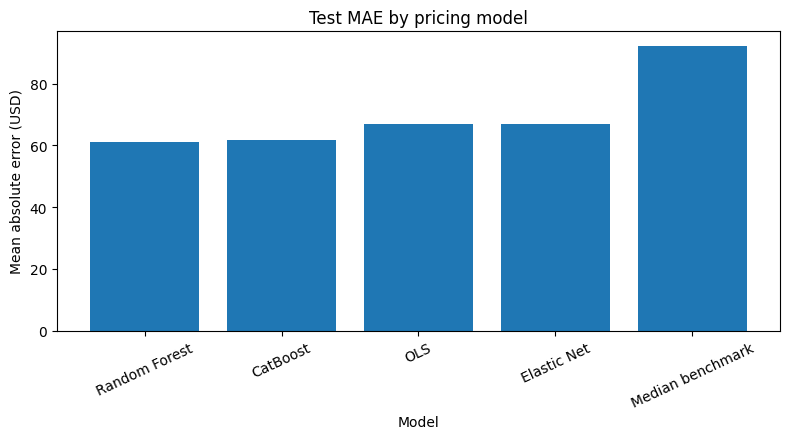

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))

plot_data = (
    model_comparison
    .sort_values("mae_usd")
)

ax.bar(
    plot_data["model"],
    plot_data["mae_usd"],
)

ax.set_title("Test MAE by pricing model")
ax.set_xlabel("Model")
ax.set_ylabel("Mean absolute error (USD)")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "model_mae_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 16. Core versus extended feature set

A separate comparison checks whether the additional review, availability, host and local-distance variables improve prediction beyond the structural core of room type and location.

OLS is used for this comparison because the change in performance can be interpreted without introducing a second tuning exercise.

In [18]:
def make_feature_preprocessor(
    categorical_columns,
    numerical_columns,
):
    return ColumnTransformer(
        [
            (
                "categorical",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="most_frequent"
                            ),
                        ),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                drop="first",
                                sparse_output=True,
                            ),
                        ),
                    ]
                ),
                categorical_columns,
            ),
            (
                "numerical",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(strategy="median"),
                        ),
                    ]
                ),
                numerical_columns,
            ),
        ]
    )


core_columns = CORE_CATEGORICAL + CORE_NUMERICAL

core_pipeline = Pipeline(
    [
        (
            "preprocessor",
            make_feature_preprocessor(
                CORE_CATEGORICAL,
                CORE_NUMERICAL,
            ),
        ),
        ("model", LinearRegression()),
    ]
)

core_cv_scores = -cross_val_score(
    core_pipeline,
    X_train[core_columns],
    y_train_log,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

core_pipeline.fit(
    X_train[core_columns],
    y_train_log,
)

core_test_log = core_pipeline.predict(
    X_test[core_columns]
)

core_metrics = regression_metrics(
    y_test_log,
    core_test_log,
    y_test_price,
)

feature_set_comparison = pd.DataFrame(
    [
        {
            "feature_set": "Core",
            "cv_rmse_log10": core_cv_scores.mean(),
            **core_metrics,
        },
        {
            "feature_set": "Extended",
            "cv_rmse_log10": model_comparison.loc[
                model_comparison["model"].eq("OLS"),
                "cv_rmse_log10",
            ].iloc[0],
            **{
                key: model_comparison.loc[
                    model_comparison["model"].eq("OLS"),
                    key,
                ].iloc[0]
                for key in [
                    "mae_log10",
                    "rmse_log10",
                    "r2_log10",
                    "mae_usd",
                    "rmse_usd",
                    "r2_usd",
                ]
            },
        },
    ]
)

display(feature_set_comparison.round(4))

,feature_set,cv_rmse_log10,mae_log10,rmse_log10,r2_log10,mae_usd,rmse_usd,r2_usd
0,Core,0.2142,0.1561,0.2186,0.5163,68.6936,233.1308,0.0929
1,Extended,0.2085,0.1511,0.2121,0.5448,66.8198,230.7788,0.1111


## 17. Final model predictions

The selected model is used to create the final test-set predictions. Actual and predicted prices are compared on the original dollar scale.

In [19]:
final_test_log = np.asarray(
    test_predictions[FINAL_MODEL_NAME]
)

final_test_price = log_to_dollars(
    final_test_log
)

prediction_table = pd.DataFrame(
    {
        "actual_price": y_test_price.to_numpy(),
        "predicted_price": final_test_price,
        "actual_log10_price": y_test_log.to_numpy(),
        "predicted_log10_price": final_test_log,
    },
    index=pricing_df.iloc[test_index].index,
)

if "id" in pricing_df.columns:
    prediction_table.insert(
        0,
        "id",
        pricing_df.iloc[test_index]["id"].to_numpy(),
    )

prediction_table["absolute_error_usd"] = (
    prediction_table["actual_price"]
    - prediction_table["predicted_price"]
).abs()

display(
    prediction_table
    .sort_values("absolute_error_usd", ascending=False)
    .head(10)
    .round(2)
)

,id,actual_price,predicted_price,actual_log10_price,predicted_log10_price,absolute_error_usd
23649,31340283,"9,999.0000",262.1800,4.0000,2.4200,"9,736.8200"
28209,34895693,"7,500.0000",59.9700,3.8800,1.7800,"7,440.0300"
26384,33796251,"4,200.0000",55.5700,3.6200,1.7400,"4,144.4300"
9132,13882394,"3,800.0000",250.7600,3.5800,2.4000,"3,549.2400"
15425,22296097,"3,210.0000",328.3200,3.5100,2.5200,"2,881.6800"
9681,14730708,"3,000.0000",403.7100,3.4800,2.6100,"2,596.2900"
27765,34592851,"2,500.0000",154.3200,3.4000,2.1900,"2,345.6800"
9192,13963005,"2,350.0000",124.8300,3.3700,2.1000,"2,225.1700"
16162,23373090,"2,500.0000",315.1100,3.4000,2.5000,"2,184.8900"
8144,12339863,"2,500.0000",476.0600,3.4000,2.6800,"2,023.9400"


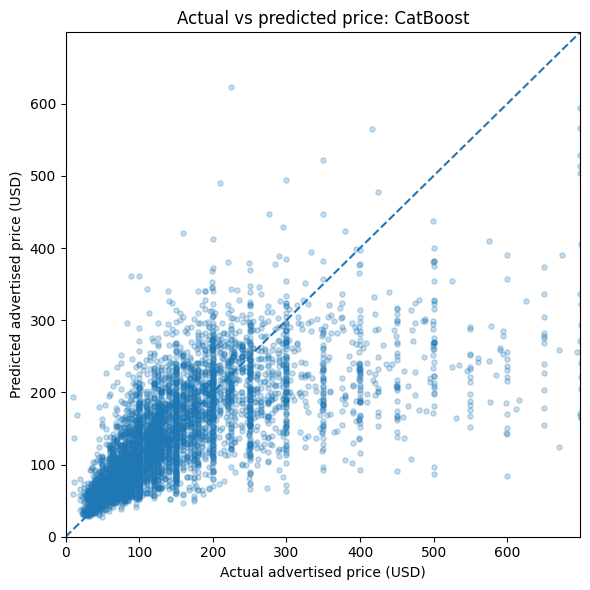

In [20]:
plot_limit = float(
    np.quantile(
        np.concatenate(
            [
                prediction_table["actual_price"].to_numpy(),
                prediction_table["predicted_price"].to_numpy(),
            ]
        ),
        0.99,
    )
)

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    prediction_table["actual_price"],
    prediction_table["predicted_price"],
    alpha=0.25,
    s=14,
)

ax.plot(
    [0, plot_limit],
    [0, plot_limit],
    linestyle="--",
)

ax.set_xlim(0, plot_limit)
ax.set_ylim(0, plot_limit)
ax.set_title(f"Actual vs predicted price: {FINAL_MODEL_NAME}")
ax.set_xlabel("Actual advertised price (USD)")
ax.set_ylabel("Predicted advertised price (USD)")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "actual_vs_predicted_price.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

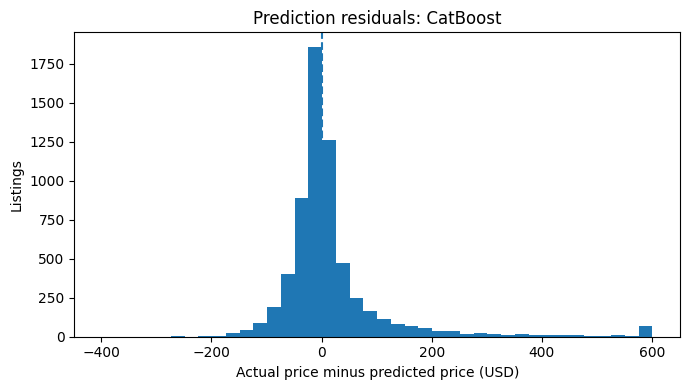

In [21]:
residual_usd = (
    prediction_table["actual_price"]
    - prediction_table["predicted_price"]
)

residual_limit = float(
    np.quantile(
        np.abs(residual_usd),
        0.99,
    )
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    residual_usd.clip(
        lower=-residual_limit,
        upper=residual_limit,
    ),
    bins=40,
)

ax.axvline(0, linestyle="--")
ax.set_title(f"Prediction residuals: {FINAL_MODEL_NAME}")
ax.set_xlabel("Actual price minus predicted price (USD)")
ax.set_ylabel("Listings")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "prediction_residuals.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 18. Error analysis

Overall model performance can hide important differences between listing types. Prediction error is therefore summarised by room type, borough and observed price band.

Price-band boundaries are calculated from the training data and then applied to the test set.

In [22]:
test_context = pricing_df.iloc[test_index].copy()

test_context["actual_price"] = y_test_price.to_numpy()
test_context["predicted_price"] = final_test_price
test_context["absolute_error_usd"] = (
    test_context["actual_price"]
    - test_context["predicted_price"]
).abs()

price_quantiles = y_train_price.quantile(
    [0.25, 0.50, 0.75]
).to_numpy()

price_bins = np.unique(
    np.concatenate(
        (
            [-np.inf],
            price_quantiles,
            [np.inf],
        )
    )
)

price_labels = [
    f"Band {i + 1}"
    for i in range(len(price_bins) - 1)
]

test_context["price_band"] = pd.cut(
    test_context["actual_price"],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True,
)

error_by_room_type = (
    test_context
    .groupby("room_type", observed=True)
    .agg(
        listings=("absolute_error_usd", "size"),
        mae_usd=("absolute_error_usd", "mean"),
        median_actual_price=("actual_price", "median"),
    )
    .sort_values("mae_usd", ascending=False)
)

error_by_borough = (
    test_context
    .groupby("neighbourhood_group", observed=True)
    .agg(
        listings=("absolute_error_usd", "size"),
        mae_usd=("absolute_error_usd", "mean"),
        median_actual_price=("actual_price", "median"),
    )
    .sort_values("mae_usd", ascending=False)
)

error_by_price_band = (
    test_context
    .groupby("price_band", observed=True)
    .agg(
        listings=("absolute_error_usd", "size"),
        mae_usd=("absolute_error_usd", "mean"),
        median_actual_price=("actual_price", "median"),
    )
)

print("Error by room type")
display(error_by_room_type.round(2))

print("Error by borough")
display(error_by_borough.round(2))

print("Error by price band")
display(error_by_price_band.round(2))

Error by room type


,listings,mae_usd,median_actual_price
room_type,,,
Entire home/apt,3272,87.1900,170.0000
Private room,2827,35.0000,70.0000
Shared room,169,21.6700,45.0000


Error by borough


,listings,mae_usd,median_actual_price
neighbourhood_group,,,
Manhattan,2688,81.2100,150.0000
Brooklyn,2466,53.0100,99.0000
Staten Island,64,38.6800,75.0000
Queens,868,35.1400,75.0000
Bronx,182,32.5800,69.5000


Error by price band


,listings,mae_usd,median_actual_price
price_band,,,
Band 1,1662,16.9400,55.0000
Band 2,1479,28.9800,90.0000
Band 3,1563,39.2200,149.0000
Band 4,1564,163.4200,260.0000


## 19. Feature importance

Feature importance is reported for the selected nonlinear model when available. For CatBoost, the model's built-in feature importance is used. For Random Forest, permutation importance is calculated on the held-out test set using the original input variables.

If a linear model is selected, the OLS coefficient table remains the main source of explanatory interpretation.

,feature,importance
0,room_type,44.7607
1,dist_center_km,11.0920
2,minimum_nights,8.5407
3,availability_365,8.4902
4,neighbourhood,5.9183
5,neighbourhood_group,5.2568
6,calculated_host_listings_count,5.1704
7,reviews_per_month,3.5082
8,number_of_reviews,2.6850
9,dist_nbhd_center_km,2.5437


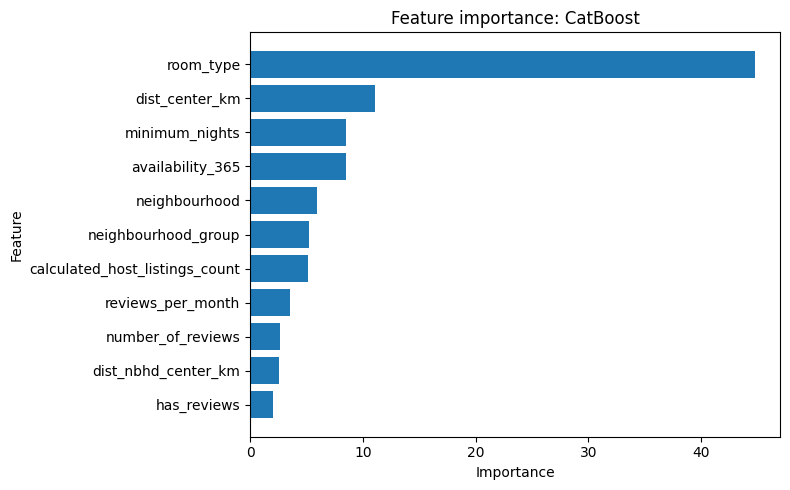

In [23]:
feature_importance_table = pd.DataFrame()

if FINAL_MODEL_NAME == "CatBoost":
    feature_importance_table = (
        pd.DataFrame(
            {
                "feature": X_train_cat.columns,
                "importance": catboost_best.get_feature_importance(),
            }
        )
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

elif FINAL_MODEL_NAME == "Random Forest":
    sample_n = min(2_000, len(X_test))

    importance_sample = X_test.sample(
        n=sample_n,
        random_state=RANDOM_SEED,
    )

    importance_target = y_test_log.loc[
        importance_sample.index
    ]

    permutation = permutation_importance(
        rf_best,
        importance_sample,
        importance_target,
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )

    feature_importance_table = (
        pd.DataFrame(
            {
                "feature": X_test.columns,
                "importance": permutation.importances_mean,
            }
        )
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

if not feature_importance_table.empty:
    display(
        feature_importance_table
        .head(15)
        .round(4)
    )

    top_importance = feature_importance_table.head(12).sort_values(
        "importance"
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(
        top_importance["feature"],
        top_importance["importance"],
    )
    ax.set_title(f"Feature importance: {FINAL_MODEL_NAME}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Feature")

    plt.tight_layout()

    fig.savefig(
        FIGURE_DIR / "final_model_feature_importance.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

## 20. Pricing model assessment

The final model is selected using training-set cross-validation rather than test performance. The held-out results then show how well that choice generalises to unseen listings.

The model comparison should be interpreted alongside the core-versus-extended feature test and the error analysis. A small predictive gain from a more complex model is less valuable if the model becomes substantially harder to explain or performs poorly for important parts of the market.

In [24]:
final_row = (
    model_comparison
    .loc[model_comparison["model"].eq(FINAL_MODEL_NAME)]
    .iloc[0]
)

print("PRICING MODEL SUMMARY")
print("---------------------")
print(f"Selected model: {FINAL_MODEL_NAME}")
print(
    f"Cross-validation RMSE (log10): "
    f"{final_row['cv_rmse_log10']:.4f}"
)
print(
    f"Test MAE: "
    f"${final_row['mae_usd']:,.2f}"
)
print(
    f"Test RMSE: "
    f"${final_row['rmse_usd']:,.2f}"
)
print(
    f"Test R²: "
    f"{final_row['r2_usd']:.3f}"
)

PRICING MODEL SUMMARY
---------------------
Selected model: CatBoost
Cross-validation RMSE (log10): 0.1902
Test MAE: $61.89
Test RMSE: $224.89
Test R²: 0.156


## 21. Save results

The comparison table, test predictions, feature-set comparison, error summaries and feature importance are saved for later analysis. The fitted models are stored separately so that the exact trained specifications can be reproduced.

In [25]:
comparison_path = OUTPUT_DIR / "model_comparison.csv"
predictions_path = OUTPUT_DIR / "test_predictions.csv"
feature_set_path = OUTPUT_DIR / "core_vs_extended_features.csv"
room_error_path = OUTPUT_DIR / "error_by_room_type.csv"
borough_error_path = OUTPUT_DIR / "error_by_borough.csv"
price_band_error_path = OUTPUT_DIR / "error_by_price_band.csv"
ols_coefficients_path = OUTPUT_DIR / "ols_coefficients.csv"
importance_path = OUTPUT_DIR / "feature_importance.csv"
metadata_path = OUTPUT_DIR / "pricing_model_metadata.json"

model_comparison.to_csv(comparison_path, index=False)
prediction_table.reset_index(drop=True).to_csv(
    predictions_path,
    index=False,
)
feature_set_comparison.to_csv(feature_set_path, index=False)
error_by_room_type.reset_index().to_csv(
    room_error_path,
    index=False,
)
error_by_borough.reset_index().to_csv(
    borough_error_path,
    index=False,
)
error_by_price_band.reset_index().to_csv(
    price_band_error_path,
    index=False,
)
ols_coefficient_table.to_csv(
    ols_coefficients_path,
    index=False,
)

if not feature_importance_table.empty:
    feature_importance_table.to_csv(
        importance_path,
        index=False,
    )

joblib.dump(
    ols_pipeline,
    MODEL_DIR / "ols_model.joblib",
)
joblib.dump(
    elastic_best,
    MODEL_DIR / "elastic_net_model.joblib",
)
joblib.dump(
    rf_best,
    MODEL_DIR / "random_forest_model.joblib",
)

catboost_best.save_model(
    str(MODEL_DIR / "catboost_model.cbm")
)

metadata = {
    "selected_model": FINAL_MODEL_NAME,
    "target": "log10(price)",
    "categorical_features": EXTENDED_CATEGORICAL,
    "numerical_features": EXTENDED_NUMERICAL,
    "random_seed": RANDOM_SEED,
    "test_size": TEST_SIZE,
    "cv_folds": CV_FOLDS,
}

with metadata_path.open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved comparison: {comparison_path}")
print(f"Saved predictions: {predictions_path}")
print(f"Saved feature comparison: {feature_set_path}")
print(f"Saved error summaries: {OUTPUT_DIR}")
print(f"Saved model files: {MODEL_DIR}")
print(f"Saved figures: {FIGURE_DIR}")

Saved comparison: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\pricing\model_comparison.csv
Saved predictions: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\pricing\test_predictions.csv
Saved feature comparison: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\pricing\core_vs_extended_features.csv
Saved error summaries: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\pricing
Saved model files: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\models\pricing
Saved figures: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\pricing\figures
